# Learning an evolution equation and stepping it forward

This notebook walks through `kernel_timestepping` on one example. From sparse observations of a solution $u(t, x)$ of

$$u_t = \kappa\, u_{xx} + \alpha\, u\, u_x, \qquad x \in (0, 1), \qquad u(t, 0) = u(t, 1) = 0,$$

it learns the right-hand side $P(u, u_x, u_{xx}, \dots)$ without being told its form, and then steps the learned
equation forward in time from initial conditions it has not seen.

| Section | What happens | Package function |
|---|---|---|
| 1 | Reference solution, grid, observations | `SpaceTimeGrid`, `sample_nodal_observations` |
| 2 | Spatial kernel basis of the state | `StateBasis` (kernel from JaxKernels) |
| 3 | Step 1: fit the state to the observations | `fit_state`, `grid_search` |
| 4 | Library of kernel modes for the operator | `build_library` |
| 5 | Step 2: fit the operator and select its atoms | `OperatorRegression`, `select_atoms` |
| 6 | Rollout of the learned equation | `ThetaStepper` |
| 7 | Refinements: two-step hard, one-step soft | `fit_two_step_operator_hard`, `fit_one_step_soft` |
| 8 | The same pipeline as one object, on other observation draws | `KMDTimeStepper.fit(method=...)` |

The algorithm is written out in [`docs/algorithm.md`](../docs/algorithm.md). To run this notebook, install the package
with `pip install -e ".[examples]"` from the repository root; the reference solver (`problems/`) and the plot style
(`experiments/plot_style.py`) are not installed and are found by the first code cell. The whole notebook runs in about three minutes on a CPU.

In [3]:
import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt
from jaxkernels import GaussianRBFKernel

import sys
from pathlib import Path

# problems/ and experiments/ are not installed with the package: put the repository root and experiments/ on the path
# (works from experiments/, from the repository root, and on Colab after cloning to /content/Kernel-Timestepping)
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents, Path("/content/Kernel-Timestepping")]
            if (p / "pyproject.toml").exists())
sys.path[:0] = [str(REPO), str(REPO / "experiments")]

import kernel_timestepping as kt
from problems.burgers_reference import ReferenceSolution, solve_burgers

import plot_style as ph
ph.use_style()

## 1. Data

The reference solution comes from a fine finite-difference solver (2001 points in $x$, time step $10^{-4}$). The method
only sees it at nodes of a coarse grid: 26 time columns $t_n = 0.04\,n$ and 31 spatial nodes $x_k$. Observed are every
node of the initial column, the two boundary nodes of every column, and 100 randomly drawn interior nodes: 181 of
the 806 nodes.

A second solution, from a different initial condition, is never shown to the fit. It is used in section 6 to test
the learned equation.

In [4]:
KAPPA, ALPHA = 0.01, 1.0                                   # the equation to learn: u_t = KAPPA u_xx + ALPHA u u_x


def sine_series(coefficients):
    """x -> sum_j c_j sin(j pi x), which vanishes at x = 0 and x = 1."""
    modes = np.arange(1, len(coefficients) + 1)
    return lambda x: np.sin(np.pi * np.outer(x, modes)) @ np.asarray(coefficients)


u0_train = sine_series([0.06, 0.08, 0.12, 0.075, 0.025])
u0_test = sine_series([-0.2, 0.1, 0.0, 0.08])
truth = ReferenceSolution(*solve_burgers(u0_train, KAPPA, ALPHA, t_final=2.0))
truth_test = ReferenceSolution(*solve_burgers(u0_test, KAPPA, ALPHA, t_final=2.0))

grid = kt.SpaceTimeGrid(x=kt.blended_chebyshev_nodes(31), dt=0.04, n_t=26)        # the fit uses t in [0, 1]
obs = kt.sample_nodal_observations(grid, lambda t, x: truth.u(t, x, grid=False), n_interior=100, seed=0)

u_true = truth.u(grid.t, grid.x)                           # (26, 31) truth at the nodes
jets_true = truth.jets(grid.t, grid.x_int)                 # (26, 29, 4) true (u, u_x, u_xx, u_xxx) at interior nodes
print(f"{grid.n_t} x {grid.n_x} = {grid.n_t * grid.n_x} nodes, {len(obs)} observed: "
      f"{obs.is_boundary(grid).sum()} boundary, {(obs.n == 0).sum() - 2} initial, {obs.is_interior(grid).sum()} interior")

26 x 31 = 806 nodes, 181 observed: 52 boundary, 29 initial, 100 interior


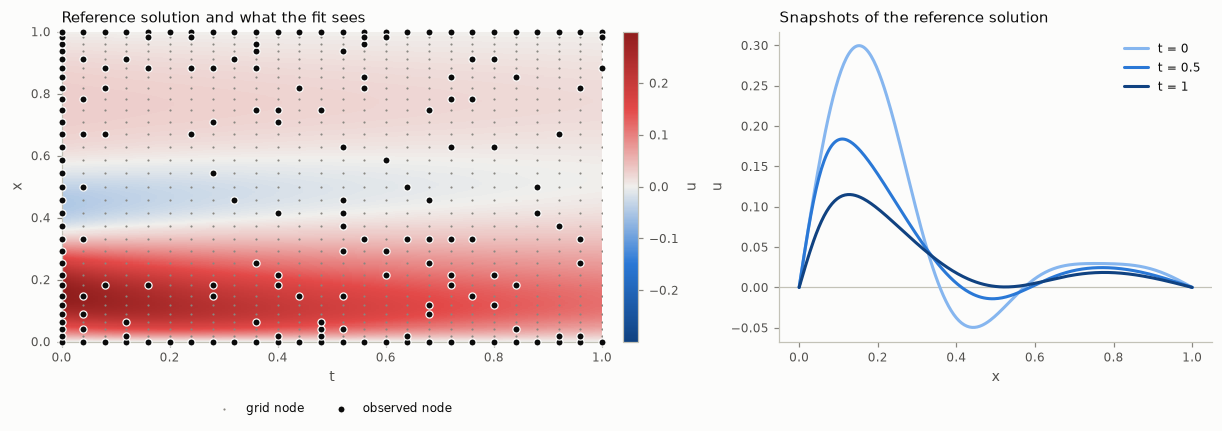

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained", width_ratios=[1.25, 1])

t_fine, x_fine = np.linspace(0, 1, 201), np.linspace(0, 1, 301)
limit = np.abs(u_true).max()
mesh = ph.field_map(axes[0], t_fine, x_fine, truth.u(t_fine, x_fine), limit, "Reference solution and what the fit sees")
t_nodes, x_nodes = np.meshgrid(grid.t, grid.x, indexing="ij")
axes[0].scatter(t_nodes, x_nodes, s=2, color=ph.MUTED, linewidths=0, label="grid node")
axes[0].scatter(grid.t[obs.n], grid.x[obs.k], s=22, color=ph.INK, edgecolors=ph.SURFACE, linewidths=0.8,
                label="observed node", clip_on=False, zorder=3)
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
fig.colorbar(mesh, ax=axes[0], pad=0.02, label="u")

snapshot_colors = ["#86b6ef", "#2a78d6", "#104281"]         # one hue, light to dark: earlier to later
for time, color in zip([0.0, 0.5, 1.0], snapshot_colors):
    axes[1].plot(x_fine, truth.u(time, x_fine)[0], color=color, label=f"t = {time:g}")
axes[1].axhline(0, color=ph.AXIS, lw=0.8, zorder=0)
axes[1].set(title="Snapshots of the reference solution", xlabel="x", ylabel="u")
axes[1].legend()
plt.show()

## 2. State basis

Each time column of the state is a kernel expansion centred at the spatial nodes,
$u_n(x) = \sum_l k(x, x_l)\,\alpha_{n,l}$, so a trajectory is an array `alpha` of shape `(N_T, N_X)`. Nodal values
and spatial derivatives at the interior nodes are linear in `alpha`: `basis.values(alpha)` is $K\alpha_n$ and
`basis.jets(alpha)` stacks $(u, u_x, u_{xx}, u_{xxx}) = (D_0\alpha_n, \dots, D_3\alpha_n)$.

The kernel is a JaxKernels `GaussianRBFKernel`; the derivative matrices $D_q$ come from the JaxKernels functional
`derivative_op(q)`. Its lengthscale follows the original notebook: fit a space-time RBF Gaussian process to the
observations by maximum marginal likelihood and use 0.75 times its space lengthscale.

In [6]:
ell_x = kt.state_lengthscale(grid, obs)
basis = kt.StateBasis.build(GaussianRBFKernel(lengthscale=ell_x), grid.x, max_order=3)
print(f"lengthscale {ell_x:.4f};  K {basis.K.shape}, D {basis.D.shape} (derivative order, interior node, centre);  "
      f"cond(K) = {np.linalg.cond(basis.K):.1e}")

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


lengthscale 0.1091;  K (31, 31), D (4, 29, 31) (derivative order, interior node, centre);  cond(K) = 3.9e+14


## 3. Step 1: fit the state

All 26 columns are fitted together:

$$\min_{\alpha}\ \sum_{(n,k)\ \mathrm{observed}} \big(y_{nk} - (K\alpha_n)_k\big)^2
  + \lambda_u \sum_n \alpha_n^\top K \alpha_n
  + \frac{\lambda_{\ddot a}}{\Delta t^4} \sum_n \big\|\alpha_{n+1} - 2\alpha_n + \alpha_{n-1}\big\|_K^2 .$$

The last term penalises the discrete acceleration $u_{tt}$ and is the only coupling between columns. Its weight
$\lambda_{\ddot a}$ is chosen by 5-fold cross-validation on the interior observations. With $\lambda_{\ddot a} = 0$
every column is fitted on its own, from about four interior observations.

In [11]:
LAM_U = 1e-6
lam_addot_grid = np.r_[0, np.logspace(-12, -1, 23)]
folds = kt.interior_folds(grid, obs, n_folds=5, seed=0)


def state_cv(lam_addot):
    return kt.heldout_rmse(lambda train: kt.fit_state(basis, grid, train, LAM_U, lam_addot), basis, obs, folds)


cv_state = kt.grid_search(lam_addot_grid, state_cv)
alpha_bar = kt.fit_state(basis, grid, obs, LAM_U, cv_state.best)             # (26, 31), row n = alpha_n
alpha_columnwise = kt.fit_state(basis, grid, obs, LAM_U, 0.0)                # for comparison: no time prior

jets_bar = np.asarray(basis.jets(alpha_bar))
print(f"chosen lam_addot = {cv_state.best:.1e}: held-out RMS error {cv_state.best_score:.2e} "
      f"(columns on their own: {cv_state.scores[0]:.2e})")
print("relative L2 error of the fitted state at the interior nodes: "
      + ",  ".join(f"{name} {kt.relative_l2(jets_bar[..., q], jets_true[..., q]):.3f}"
                   for q, name in enumerate(["u", "u_x", "u_xx", "u_xxx"])))

chosen lam_addot = 1.0e-08: held-out RMS error 1.25e-03 (columns on their own: 6.69e-02)
relative L2 error of the fitted state at the interior nodes: u 0.010,  u_x 0.026,  u_xx 0.083,  u_xxx 0.367


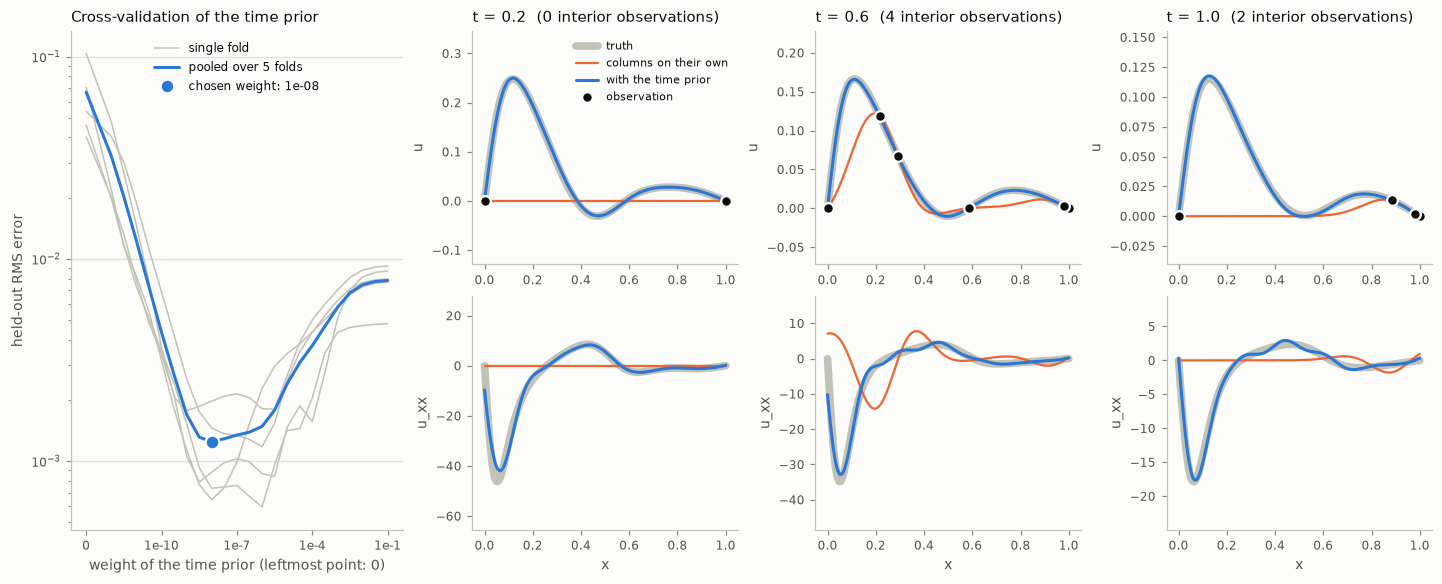

In [12]:
fig = plt.figure(figsize=(13, 5.2), layout="constrained")
panels = fig.add_gridspec(2, 4, width_ratios=[1.25, 1, 1, 1])

ax = fig.add_subplot(panels[:, 0])
positive = cv_state.values[1:]
positions = np.r_[positive[0] / 10, positive]                # lam_addot = 0 is drawn one decade left of the grid
ax.plot(positions, cv_state.fold_scores, color=ph.NEUTRAL, lw=1)
ax.plot([], [], color=ph.NEUTRAL, lw=1, label="single fold")
ax.plot(positions, cv_state.scores, color=ph.BLUE, label="pooled over 5 folds")
ph.marker(ax, positions[cv_state.best_index], cv_state.best_score, ph.BLUE, ms=9, ls="none",
          label=f"chosen weight: {cv_state.best:.0e}")
ax.set(xscale="log", yscale="log", xlabel="weight of the time prior (leftmost point: 0)",
       ylabel="held-out RMS error", title="Cross-validation of the time prior")
ax.set_xticks([positions[0], 1e-10, 1e-7, 1e-4, 1e-1], ["0", "1e-10", "1e-7", "1e-4", "1e-1"])
ax.grid(True, axis="y")
ax.legend(loc="upper center")

derivative_names = {0: "u", 2: "u_xx"}
for row, order in enumerate(derivative_names):
    B = basis.matrix(x_fine, order)                          # (301, 31): basis functions (or derivatives) on a fine grid
    reference = truth.u if order == 0 else truth.u_xx
    for col, n in enumerate([5, 15, 25]):
        ax = fig.add_subplot(panels[row, col + 1])
        exact = reference(grid.t[n], x_fine)[0]
        ax.plot(x_fine, exact, color=ph.NEUTRAL, lw=5, label="truth")
        ax.plot(x_fine, B @ alpha_columnwise[n], color=ph.ORANGE, lw=1.5, label="columns on their own")
        ax.plot(x_fine, B @ alpha_bar[n], color=ph.BLUE, label="with the time prior")
        if order == 0:
            here = obs.n == n
            ax.plot(grid.x[obs.k[here]], obs.y[here], "o", color=ph.INK, mec=ph.SURFACE, mew=1.5, ms=7,
                    label="observation", zorder=4)
            ax.set_title(f"t = {grid.t[n]:.1f}  ({(here & obs.is_interior(grid)).sum()} interior observations)")
        span = exact.max() - exact.min()
        ax.set(ylim=(exact.min() - 0.35 * span, exact.max() + 0.35 * span), ylabel=derivative_names[order])
        if row == 1:
            ax.set_xlabel("x")
        if row == 0 and col == 0:
            ax.legend(loc="upper right", fontsize=7)
plt.show()

## 4. Operator library

The operator is modelled as a sum of **atoms**. An atom is a function of *one* scalar feature of the state, taken
from the RKHS of *one* scalar kernel:

$$\hat P(s) = \sum_m \hat P_m\big(z_{i(m)}\big), \qquad \hat P_m(z) = \sum_j k_m(z, \zeta_{mj})\,\beta_{mj},$$

where $s = (u, u_x, u_{xx}, u_{xxx})$, $z_i$ is feature $i$ standardised with the mean and standard deviation it has
on the Step-1 state, and $\zeta_{mj}$ are inducing points spread over the range of that feature. The kernels are
JaxKernels kernels: `LinearKernel` gives a term linear in the feature (one coefficient), `GaussianRBFKernel` and
`MaternKernel(p=1)` give a general smooth or rougher function of it (15 coefficients each).

In [13]:
library = kt.build_library(basis.jets(alpha_bar), n_inducing=15)

print(f"{len(library.atoms)} atoms, {library.n_coef} coefficients\n")
print(f"{'feature':8s} {'mean':>10s} {'std':>10s}   coefficients per atom")
for i, feature in enumerate(library.features):
    on_feature = [atom for atom in library.atoms if atom.feature == i]
    print(f"{feature.name:8s} {library.center[i]:10.3g} {library.scale[i]:10.3g}   "
          + ", ".join(f"{atom.name.split('[')[0]} {atom.size}" for atom in on_feature))
print(f"{'(none)':8s} {'':>10s} {'':>10s}   const 1")

19 atoms, 187 coefficients

feature        mean        std   coefficients per atom
u            0.0542     0.0707   linear 1, rbf 15, matern32 15
u_x          0.0716      0.872   linear 1, rbf 15, matern32 15
u_xx           -4.6         11   linear 1, rbf 15, matern32 15
u_xxx          5.85        163   linear 1, rbf 15, matern32 15
u*u_x       0.00978      0.104   linear 1, rbf 15, matern32 15
u^2         0.00794     0.0154   linear 1, rbf 15, matern32 15
(none)                           const 1


## 5. Step 2: fit the operator and select its atoms

State and operator are tied by one Crank-Nicolson step. With $r(\alpha; b)$ the operator evaluated at the interior
nodes (zero at the two boundary nodes), the dynamic residual of step $n$ is

$$e_n = K(\alpha_{n+1} - \alpha_n) - \Delta t\,\big[\tfrac12\, r(\alpha_{n+1}; b) + \tfrac12\, r(\alpha_n; b)\big].$$

With the state frozen at the Step-1 fit, $e_n$ is linear in the coefficients $b$, so
$\sum_n \|e_n\|^2 + \lambda_\beta \sum_m \beta_m^\top K_m \beta_m$ has a closed-form minimiser for any subset of atoms.

`select_atoms` chooses the subset by **backward elimination**: start from all 18 non-constant atoms and repeatedly
drop the one whose removal gives the lowest cross-validation error (5 contiguous blocks of time steps held out in
turn; $\lambda_\beta$ re-chosen for every candidate). The **one-standard-error rule** then picks the smallest set on
that path whose error is within one standard error of the best.

In [14]:
regression = kt.OperatorRegression.from_state(basis, library, alpha_bar, grid.dt, theta=0.5)
selection = kt.select_atoms(regression, lam_grid=np.logspace(-12, 2, 15), n_blocks=5)

active = library.restrict(selection.atoms)                  # the library with the selected atoms only
coef_soft = selection.coef                                  # their coefficients (standardised units)


def describe(library, coef):
    """The fitted operator in the original units of the features."""
    slopes, constant = library.linear_coefficients(coef)
    text = f"{constant:+.2e} " + " ".join(f"{value:+.4g} {name}" for name, value in slopes.items())
    kernel_atoms = [atom.name for atom in library.atoms if atom.size > 1]
    return text + (" + " + " + ".join(kernel_atoms) if kernel_atoms else "")


n_atoms = lambda step: sum(library.atoms[m].prunable for m in step.atoms)
best = selection.path[selection.i_min]
print(f"lowest CV error on the path: {best.cv:.2e} +- {best.se:.1e} with {n_atoms(best)} atoms")
print(f"one-standard-error rule:     {selection.selected.cv:.2e} with {n_atoms(selection.selected)} atoms "
      f"(lam_beta = {selection.lam_beta:.0e}): {', '.join(active.names)}")
print(f"\nlearned  P = {describe(active, coef_soft)}")
print(f"true     P = {KAPPA:+.4g} u_xx {ALPHA:+.4g} u*u_x")

lowest CV error on the path: 6.27e-04 +- 1.2e-04 with 2 atoms
one-standard-error rule:     6.27e-04 with 2 atoms (lam_beta = 1e-12): const, linear[u_xx], linear[u*u_x]

learned  P = -3.54e-04 +0.009894 u_xx +0.9558 u*u_x
true     P = +0.01 u_xx +1 u*u_x


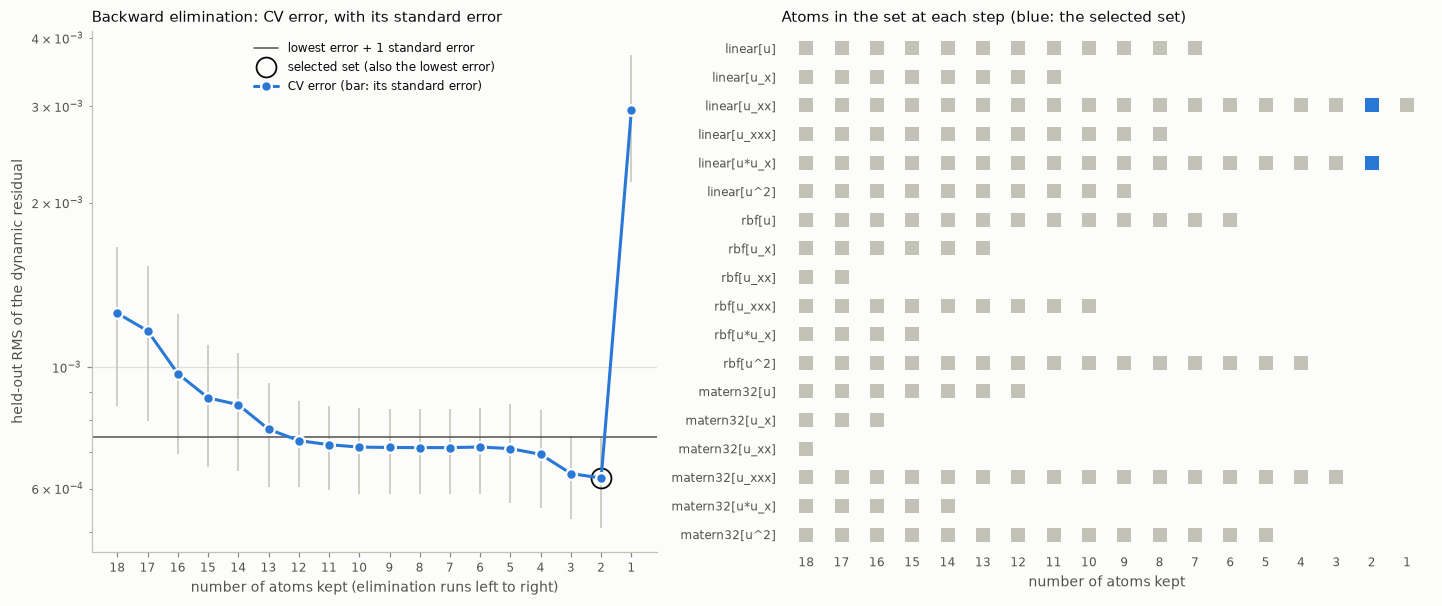

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), layout="constrained", width_ratios=[1, 1.15])
path = selection.path
sizes = np.array([n_atoms(step) for step in path])
errors, standard_errors = np.array([step.cv for step in path]), np.array([step.se for step in path])

ax = axes[0]
ax.errorbar(sizes, errors, yerr=standard_errors, color=ph.BLUE, ecolor=ph.NEUTRAL, elinewidth=1, capsize=0,
            marker="o", mec=ph.SURFACE, mew=1.5, ms=7, label="CV error (bar: its standard error)")
ax.axhline(selection.threshold, color=ph.SECONDARY, lw=1, label="lowest error + 1 standard error")
same = selection.i_min == selection.i_sel
ax.plot(sizes[selection.i_sel], errors[selection.i_sel], "o", ms=13, mfc="none", mec=ph.INK, mew=1.2, ls="none",
        label="selected set" + (" (also the lowest error)" if same else ""))
if not same:
    ax.plot(sizes[selection.i_min], errors[selection.i_min], "s", ms=12, mfc="none", mec=ph.SECONDARY, mew=1.2,
            ls="none", label="lowest error")
ax.legend(loc="upper center")
ax.invert_xaxis()
ax.set(yscale="log", xticks=sizes[::-1], xlabel="number of atoms kept (elimination runs left to right)",
       ylabel="held-out RMS of the dynamic residual", title="Backward elimination: CV error, with its standard error")
ax.grid(True, axis="y")

ax = axes[1]
prunable = [m for m, atom in enumerate(library.atoms) if atom.prunable]
for column, step in enumerate(path):
    kept = [row for row, m in enumerate(prunable) if m in step.atoms]
    ax.scatter(np.full(len(kept), column), kept, marker="s", s=95, linewidths=0,
               color=ph.BLUE if column == selection.i_sel else ph.NEUTRAL)
ax.set(xlim=(-0.7, len(path) - 0.3), ylim=(len(prunable) - 0.4, -0.6), xlabel="number of atoms kept",
       title="Atoms in the set at each step (blue: the selected set)")
ax.set_xticks(range(len(path)), sizes)
ax.set_yticks(range(len(prunable)), [library.atoms[m].name for m in prunable])
ax.tick_params(length=0)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
plt.show()

## 6. Rollout

`ThetaStepper` turns the learned operator into a time stepper. One step solves $e_n = 0$ for $\alpha_{n+1}$ with a
fixed number of Newton iterations; a rollout repeats the step. Nothing but the initial condition enters.

Two tests, both run to $t = 2$, twice as far as the data used for the fit:

* the **training** initial condition, whose solution was observed sparsely on $t \le 1$;
* a **new** initial condition that the fit never saw.

As a yardstick, the true equation is put through the same stepper. Its error is what the coarse grid and the
time step cost on their own.

In [16]:
N_ROLL = 50
t_roll = grid.dt * np.arange(N_ROLL + 1)
stepper = kt.ThetaStepper(basis, active.evaluate, grid.dt, theta=0.5)
true_stepper = kt.ThetaStepper(basis, lambda jets, _: KAPPA * jets[..., 2] + ALPHA * jets[..., 0] * jets[..., 1], grid.dt)


def rollout(stepper, coef, u0_nodes):
    """Nodal values (N_ROLL + 1, N_X) of the rollout from the initial nodal values u0_nodes."""
    alpha0 = basis.interpolate(u0_nodes)                    # coefficients with K alpha0 = u0
    coef = None if coef is None else jnp.asarray(coef)
    return np.asarray(basis.values(stepper.rollout(alpha0, coef, N_ROLL)))


cases = {"training initial condition": truth.u(t_roll, grid.x), "new initial condition": truth_test.u(t_roll, grid.x)}
rollouts = {name: rollout(stepper, coef_soft, exact[0]) for name, exact in cases.items()}
floors = {name: rollout(true_stepper, None, exact[0]) for name, exact in cases.items()}

in_data = t_roll <= grid.t[-1]
print(f"relative L2 error of the rollout at the nodes {'t <= 1':>12s} {'t <= 2':>10s}")
for name, exact in cases.items():
    for label, values in [("learned equation", rollouts[name]), ("true equation, same stepper", floors[name])]:
        print(f"  {name + ', ' + label:54s} {kt.relative_l2(values[in_data], exact[in_data]):8.4f} "
              f"{kt.relative_l2(values, exact):10.4f}")

relative L2 error of the rollout at the nodes       t <= 1     t <= 2
  training initial condition, learned equation             0.0090     0.0108
  training initial condition, true equation, same stepper   0.0005     0.0005
  new initial condition, learned equation                  0.0067     0.0108
  new initial condition, true equation, same stepper       0.0002     0.0002


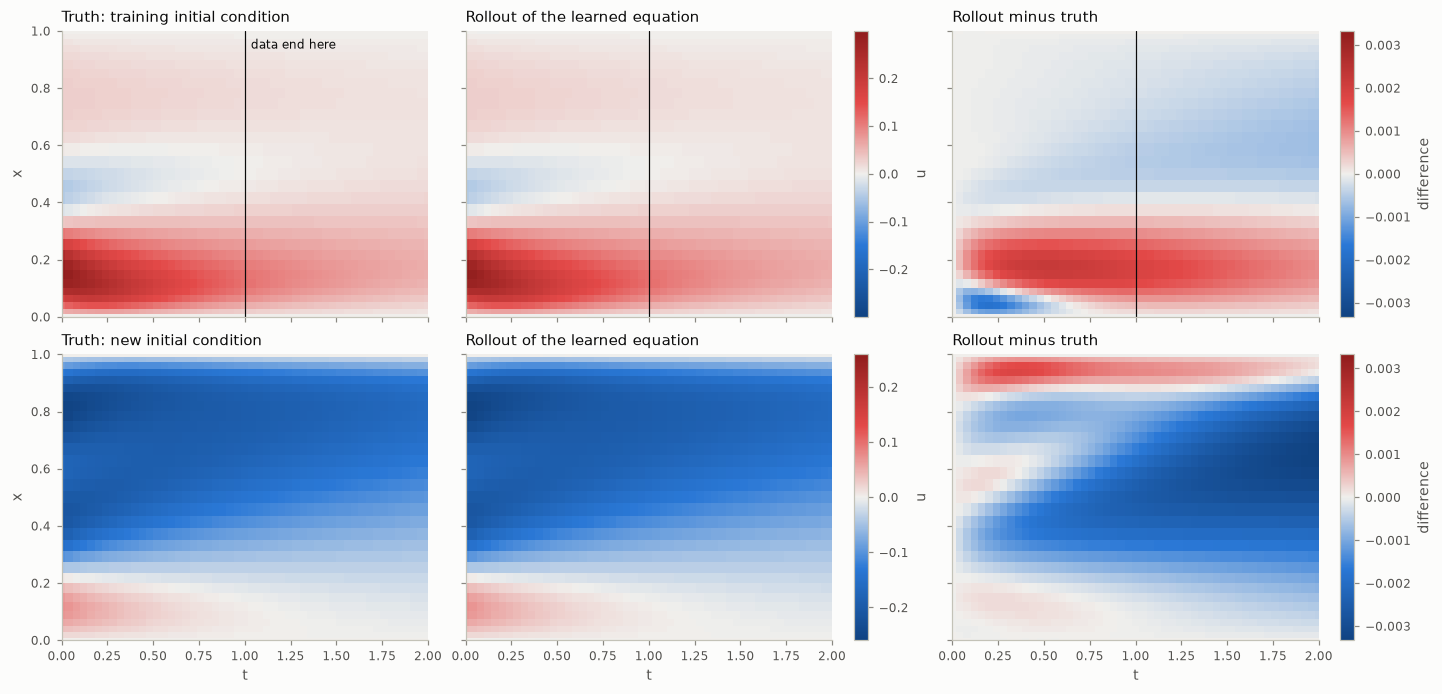

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.2), layout="constrained", sharex=True, sharey=True)
difference_limit = max(np.abs(rollouts[name] - exact).max() for name, exact in cases.items())
for row, (name, exact) in enumerate(cases.items()):
    limit = np.abs(exact).max()
    field = ph.field_map(axes[row, 0], t_roll, grid.x, exact, limit, f"Truth: {name}")
    ph.field_map(axes[row, 1], t_roll, grid.x, rollouts[name], limit, "Rollout of the learned equation")
    delta = ph.field_map(axes[row, 2], t_roll, grid.x, rollouts[name] - exact, difference_limit, "Rollout minus truth")
    fig.colorbar(field, ax=axes[row, :2], pad=0.01, label="u")
    fig.colorbar(delta, ax=axes[row, 2], pad=0.02, label="difference")
for ax in axes[0]:
    ax.axvline(grid.t[-1], color=ph.INK, lw=0.8)
axes[0, 0].annotate("data end here", (grid.t[-1], 0.97), textcoords="offset points", xytext=(4, -6), fontsize=8)
for ax in axes.ravel():
    ax.label_outer()
plt.show()

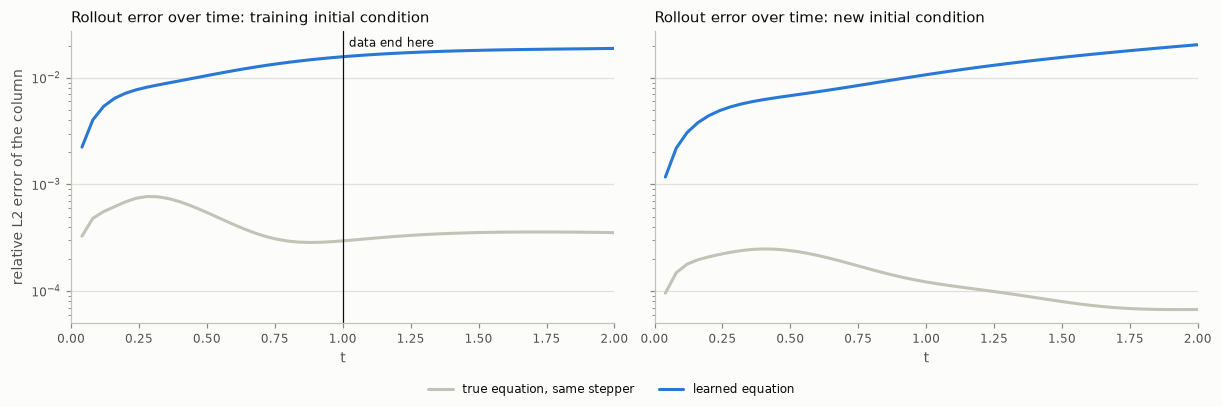

In [18]:
def error_per_column(values, exact):
    """Relative L2 error of each time column (the initial column is exact by construction and is left out)."""
    return np.linalg.norm(values - exact, axis=1)[1:] / np.linalg.norm(exact, axis=1)[1:]


fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained", sharey=True)
for ax, (name, exact) in zip(axes, cases.items()):
    ax.plot(t_roll[1:], error_per_column(floors[name], exact), color=ph.NEUTRAL, label="true equation, same stepper")
    ax.plot(t_roll[1:], error_per_column(rollouts[name], exact), color=ph.BLUE, label="learned equation")
    ax.set(yscale="log", xlabel="t", title=f"Rollout error over time: {name}", xlim=(0, t_roll[-1]))
    ax.grid(True, axis="y")
axes[0].axvline(grid.t[-1], color=ph.INK, lw=0.8)
axes[0].annotate("data end here", (grid.t[-1], 1), xycoords=("data", "axes fraction"), textcoords="offset points",
                 xytext=(4, -10), fontsize=8)
axes[0].set_ylabel("relative L2 error of the column")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2)
plt.show()

In the saved run the learned equation stays within about 1 to 2 % of the truth out to $t = 2$ for both initial
conditions, and the error grows steadily. The grey curves show that the stepper is not what limits it: over
$t \le 2$ the true equation in the same stepper has an error 20 to 50 times smaller (table above). The limit is the
fitted coefficient of $u\,u_x$, which Step 2 underestimates by about 4 %.

## 7. Refinements

Step 2 fitted the coefficients to *one-step* residuals of a state that was itself fitted without knowing the
equation. The package has two ways to tighten that, both for the atom set already selected.

**Two-step, hard constraint** (`fit_two_step_operator_hard`): fit the operator through the rollout. Keep the Step-1 state, but
choose the coefficients so that the rollout from its first column reproduces every later column. The dynamics then
hold exactly, and the fit sees accumulated error instead of one-step error.

**One-step, soft constraint** (`fit_one_step_soft`): the joint fit. Fit state and coefficients together: data misfit
$+\ \lambda_{\rm dyn}\sum_n \|e_n\|^2$ + the regularisers. The equation now helps to reconstruct the state between
observations. $\lambda_{\rm dyn}$ is chosen by the same 5-fold cross-validation on held-out observations as in Step 1.

In [19]:
coef_hard, fit_hard = kt.fit_two_step_operator_hard(stepper, active, alpha_bar, coef_soft, lam_beta=1e-6)

lam_dyn_grid = np.logspace(-3, 1, 5)


def joint_fit(train, lam_dyn, maxiter):
    return kt.fit_one_step_soft(stepper, active, grid, train, alpha_bar, coef_soft, kt.OneStepWeights(dyn=lam_dyn),
                             maxiter=maxiter)


cv_joint = kt.grid_search(lam_dyn_grid, lambda lam_dyn: kt.heldout_rmse(
    lambda train: joint_fit(train, lam_dyn, maxiter=5000)[0], basis, obs, folds))
alpha_joint, coef_joint, fit_joint = joint_fit(obs, cv_joint.best, maxiter=20000)
print(f"chosen lam_dyn = {cv_joint.best:g}: held-out RMS error {cv_joint.best_score:.2e} (Step 1: {cv_state.best_score:.2e})")

chosen lam_dyn = 1: held-out RMS error 8.91e-05 (Step 1: 1.25e-03)


In [14]:
# P_hat at the TRUE (u, u_x, u_xx, u_xxx) against the true u_t on a 100 x 100 grid inside the domain
inner = np.linspace(0, 1, 104)[2:-2]
jets_inner, ut_inner = truth.jets(inner, inner).reshape(-1, 4), truth.u_t(inner, inner).ravel()


def operator_error(coef):
    predicted = np.asarray(active.evaluate(jnp.asarray(jets_inner), jnp.asarray(coef)))
    return np.sqrt(np.mean((predicted - ut_inner) ** 2) / np.mean(ut_inner ** 2))


variants = {"two-step (section 5)": (coef_soft, alpha_bar), "fit through the rollout": (coef_hard, alpha_bar),
            "joint fit": (coef_joint, alpha_joint)}
test_exact = cases["new initial condition"]
test_rollouts = {name: rollout(stepper, coef, test_exact[0]) for name, (coef, _) in variants.items()}

print(f"{'':26s} {'kappa':>9s} {'alpha':>8s} {'constant':>10s} {'operator':>9s} {'state u_xx':>11s} {'rollout':>9s}")
print(f"{'truth':26s} {KAPPA:9.5f} {ALPHA:8.4f} {0:10.1e}")
for name, (coef, alpha) in variants.items():
    slopes, constant = active.linear_coefficients(coef)
    state_error = kt.relative_l2(np.asarray(basis.jets(alpha))[..., 2], jets_true[..., 2])
    print(f"{name:26s} {slopes.get('u_xx', np.nan):9.5f} {slopes.get('u*u_x', np.nan):8.4f} {constant:10.1e} {operator_error(coef):9.4f} "
          f"{state_error:11.4f} {kt.relative_l2(test_rollouts[name], test_exact):9.4f}")
print("\noperator: relative error of P_hat at the true features;  state u_xx: relative error of the fitted u_xx;")
print("rollout: relative error of the rollout from the new initial condition, t <= 2")

                               kappa    alpha   constant  operator  state u_xx   rollout
truth                        0.01000   1.0000    0.0e+00


two-step (section 5)         0.00989   0.9558   -3.5e-04    0.0376      0.0828    0.0108
fit through the rollout      0.01000   0.9862    1.0e-05    0.0140      0.0828    0.0030
joint fit                    0.01001   0.9932   -2.2e-05    0.0073      0.0184    0.0016

operator: relative error of P_hat at the true features;  state u_xx: relative error of the fitted u_xx;
rollout: relative error of the rollout from the new initial condition, t <= 2


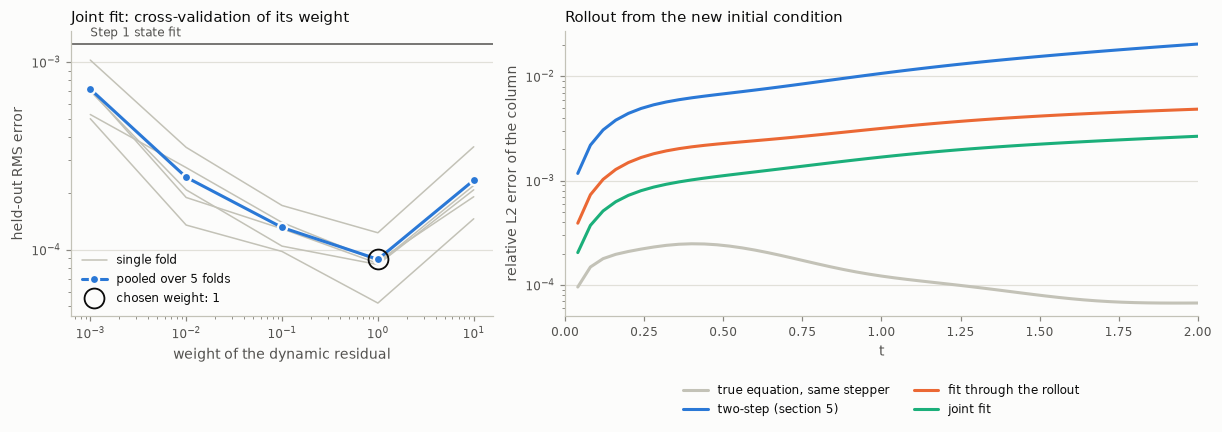

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained", width_ratios=[1, 1.5])

ax = axes[0]
ax.plot(cv_joint.values, cv_joint.fold_scores, color=ph.NEUTRAL, lw=1)
ax.plot([], [], color=ph.NEUTRAL, lw=1, label="single fold")
ax.plot(cv_joint.values, cv_joint.scores, color=ph.BLUE, marker="o", mec=ph.SURFACE, mew=1.5, label="pooled over 5 folds")
ax.plot(cv_joint.best, cv_joint.best_score, "o", ms=13, mfc="none", mec=ph.INK, mew=1.2, ls="none",
        label=f"chosen weight: {cv_joint.best:g}")
ax.axhline(cv_state.best_score, color=ph.SECONDARY, lw=1)
ax.annotate("Step 1 state fit", (cv_joint.values[0], cv_state.best_score), textcoords="offset points", xytext=(0, 5),
            color=ph.SECONDARY, fontsize=8)
ax.set(xscale="log", yscale="log", xlabel="weight of the dynamic residual", ylabel="held-out RMS error",
       title="Joint fit: cross-validation of its weight")
ax.grid(True, axis="y")
ax.legend(loc="lower left")

ax = axes[1]
ax.plot(t_roll[1:], error_per_column(floors["new initial condition"], test_exact), color=ph.NEUTRAL,
        label="true equation, same stepper")
for (name, values), color in zip(test_rollouts.items(), [ph.BLUE, ph.ORANGE, ph.AQUA]):
    ax.plot(t_roll[1:], error_per_column(values, test_exact), color=color, label=name)
ax.set(yscale="log", xlabel="t", ylabel="relative L2 error of the column", xlim=(0, t_roll[-1]),
       title="Rollout from the new initial condition")
ax.grid(True, axis="y")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.show()

In the saved run both refinements pull the coefficient of $u\,u_x$ towards 1 and cut the rollout error, by a factor
of about 4 (fit through the rollout) and 7 (joint fit). The joint fit also improves the state itself: the error of
the reconstructed $u_{xx}$ drops from 8 % to 2 %.

The package also has the fourth variant of the original notebook, `fit_one_step_hard` ("one-step, hard constraint"):
the unknowns are the first column and the coefficients, and every later column is their rollout. It is not used
here, for a reason the next cell shows. Its loss keeps the state-norm term
$\lambda_\alpha \sum_n \alpha_n^\top K \alpha_n$, now on rolled-out columns. Every step of a rollout solves a
linear system with a matrix close to $K$, and with this lengthscale $K$ is very badly conditioned (section 2), so
the rolled-out columns have a huge norm even when they match the data. At the weight the original notebook uses
($\lambda_\alpha = 10^{-6}$) the norm term then outweighs the data misfit by many orders of magnitude and decides
the fit.

In [16]:
alpha_rolled = np.asarray(stepper.rollout(jnp.asarray(alpha_joint[0]), jnp.asarray(coef_joint), grid.n_steps))
misfit = np.sum((np.asarray(basis.values(alpha_rolled))[obs.n, obs.k] - obs.y) ** 2)
norm_fitted, norm_rolled = (np.sum(basis.whiten(a) ** 2) for a in (alpha_joint, alpha_rolled))
print("joint-fit solution, rolled out from its first column:")
print(f"  data misfit                         {misfit:.1e}")
print(f"  1e-6 * state norm, rolled-out state {1e-6 * norm_rolled:.1e}")
print(f"  1e-6 * state norm, fitted state     {1e-6 * norm_fitted:.1e}")

joint-fit solution, rolled out from its first column:
  data misfit                         1.2e-06
  1e-6 * state norm, rolled-out state 3.2e+03
  1e-6 * state norm, fitted state     1.1e-05


## 8. The pipeline as one object, and other observation draws

`KMDTimeStepper` wires sections 2 to 6 together: `fit` runs Step 1, builds the library and selects the atoms;
`rollout` steps the learned equation forward from nodal values of an initial condition.

Which 100 interior nodes are observed is random. The loop below repeats the fit for five draws. Seed 0 is the draw
used above, so its row must reproduce section 5.

In [17]:
rows = []
for seed in range(5):
    obs_seed = kt.sample_nodal_observations(grid, lambda t, x: truth.u(t, x, grid=False), n_interior=100, seed=seed)
    kernel = GaussianRBFKernel(lengthscale=kt.state_lengthscale(grid, obs_seed))
    model = kt.KMDTimeStepper(kernel, grid).fit(obs_seed)
    error = kt.relative_l2(model.rollout(test_exact[0], n_steps=N_ROLL), test_exact)
    rows.append((seed, model, error))
    if seed == 0:
        assert model.library_.names == active.names and np.allclose(model.coef_, coef_soft)

print(f"{'seed':>4s} {'lengthscale':>12s} {'rollout':>8s}   learned operator")
for seed, model, error in rows:
    print(f"{seed:4d} {float(model.basis.kernel.lengthscale):12.4f} {error:8.4f}   "
          f"{describe(model.library_, model.coef_)}")
print("\nrollout: relative error from the new initial condition, t <= 2")

seed  lengthscale  rollout   learned operator
   0       0.1091   0.0108   -3.54e-04 +0.009894 u_xx +0.9558 u*u_x
   1       0.1141   0.0341   +1.82e-02 +0.00956 u_xx +0.9056 u*u_x + rbf[u_xxx]
   2       0.1079   0.0145   -6.75e-04 +0.009809 u_xx +0.9471 u*u_x
   3       0.1156   0.0468   +1.63e-02 +0.009384 u_xx +0.8945 u*u_x + matern32[u_xxx]
   4       0.1099   0.0104   -4.10e-04 +0.009789 u_xx +0.9631 u*u_x

rollout: relative error from the new initial condition, t <= 2


In the saved run every draw finds the two true terms, $u_{xx}$ and $u\,u_x$, as linear atoms. Three of the five
draws select exactly those. The other two keep one extra kernel atom on $u_{xxx}$, the least accurately
reconstructed feature, and have the larger rollout errors (3 to 5 % against 1 to 1.5 %). The selection is
data-driven and does depend on which nodes happen to be observed.

## Where to go from here

* **Other features or kernels.** `build_library(jets, features=..., kernels=...)` takes any functions of the jet and
  any JaxKernels kernels on scalars, e.g. `{"linear": LinearKernel(), "matern52": MaternKernel(p=2)}`.
* **Other state kernels.** `StateBasis.build` accepts any JaxKernels kernel on scalars that is `max_order` times
  differentiable in its first argument, e.g. `MaternKernel(p=4, lengthscale=0.2)`.
* **Other time schemes.** `ThetaStepper(..., theta=1.0)` is backward Euler; `theta=0.5` is Crank-Nicolson.
* **Other equations.** Nothing in the package is specific to this equation except `problems/burgers_reference.py`,
  which only produces the reference data.